# 02 — EDA: Eksplorasi Data Ulasan Access by KAI

Memahami struktur dan sebaran data mentah **sebelum** diproses:
distribusi bintang, label sentimen, panjang ulasan, kata tersering, dan wordcloud.

Input: `data/raw/reviews_access_by_kai.csv`

In [1]:
from collections import Counter
from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from wordcloud import WordCloud

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

ROOT = Path.cwd()
while not (ROOT / "README.md").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent

df = pd.read_csv(ROOT / "data" / "raw" / "reviews_access_by_kai.csv")
print("Bentuk data:", df.shape)
print("Kolom:", list(df.columns))

Bentuk data: (5000, 10)
Kolom: ['reviewId', 'userName', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at', 'replyContent', 'repliedAt', 'scraped_at']


In [2]:
print("Ulasan kosong     :", (df["content"].fillna("").str.strip() == "").sum())
print("reviewId ganda    :", df["reviewId"].duplicated().sum())
print("Tanggal terawal   :", df["at"].min())
print("Tanggal terbaru   :", df["at"].max())
df[["score", "thumbsUpCount"]].describe()

Ulasan kosong     : 0
reviewId ganda    : 0
Tanggal terawal   : 2026-04-26 15:22:12
Tanggal terbaru   : 2026-10-08 22:50:15


,score,thumbsUpCount
count,5000.00000,5000.000000
mean,3.29460,0.436600
std,1.81738,5.293466
min,1.00000,0.000000
25%,1.00000,0.000000
50%,4.00000,0.000000
75%,5.00000,0.000000
max,5.00000,327.000000


score
1    1673
2     302
3     319
4     291
5    2415
Name: count, dtype: int64


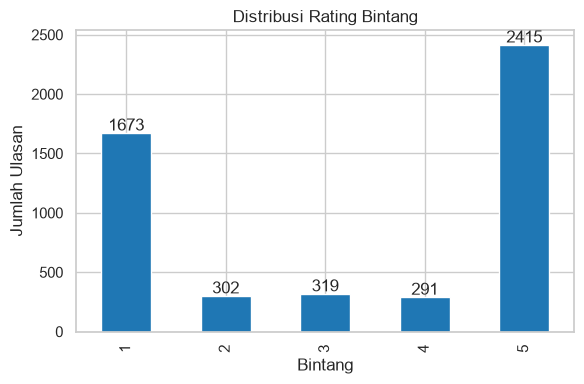

In [3]:
counts = df["score"].value_counts().sort_index()
print(counts)

ax = counts.plot(kind="bar", color="#1f77b4", figsize=(6, 4))
ax.set_title("Distribusi Rating Bintang")
ax.set_xlabel("Bintang")
ax.set_ylabel("Jumlah Ulasan")
for i, v in enumerate(counts.values):
    ax.text(i, v + 20, str(v), ha="center")
plt.tight_layout()
plt.show()

sentimen
positif    2706
negatif    1975
netral      319
Name: count, dtype: int64

Rasio biner positif:negatif = 2706 : 1975


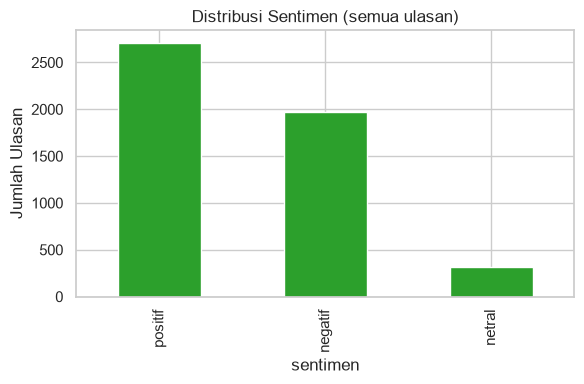

In [4]:
def label_sentimen(score):
    if score >= 4:
        return "positif"
    if score <= 2:
        return "negatif"
    return "netral"

df["sentimen"] = df["score"].map(label_sentimen)
print(df["sentimen"].value_counts())

biner = df[df["sentimen"] != "netral"]
print("\nRasio biner positif:negatif =", 
      f"{(biner['sentimen']=='positif').sum()} : {(biner['sentimen']=='negatif').sum()}")

ax = df["sentimen"].value_counts().plot(kind="bar", color="#2ca02c", figsize=(6, 4))
ax.set_title("Distribusi Sentimen (semua ulasan)")
ax.set_ylabel("Jumlah Ulasan")
plt.tight_layout()
plt.show()

       n_karakter       n_kata
count  5000.00000  5000.000000
mean     73.41600    11.742200
std      91.22933    14.473619
min       1.00000     1.000000
25%      12.00000     2.000000
50%      38.00000     6.000000
75%     100.00000    16.000000
max     500.00000    87.000000


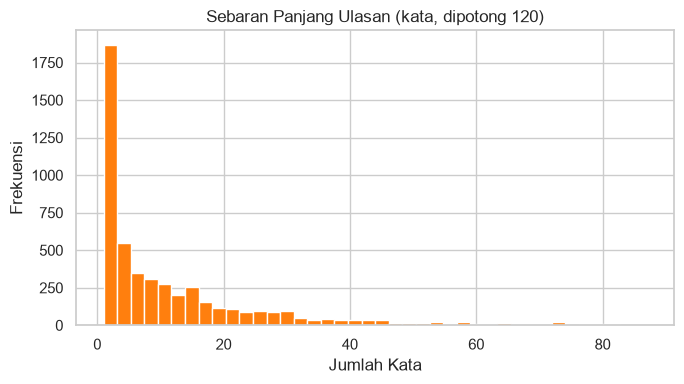

In [5]:
df["n_karakter"] = df["content"].fillna("").str.len()
df["n_kata"] = df["content"].fillna("").str.split().map(len)
print(df[["n_karakter", "n_kata"]].describe())

ax = df["n_kata"].clip(upper=120).plot(kind="hist", bins=40, figsize=(7, 4), color="#ff7f0e")
ax.set_title("Sebaran Panjang Ulasan (kata, dipotong 120)")
ax.set_xlabel("Jumlah Kata")
ax.set_ylabel("Frekuensi")
plt.tight_layout()
plt.show()

          tiket : 1213
       aplikasi : 966
            mau : 588
            nya : 581
            kai : 554
         kereta : 545
         sangat : 531
          bagus : 439
            gak : 410
         jadwal : 366
         sering : 361
          mudah : 343
          malah : 339
         banget : 307
           udah : 286
        padahal : 284
            aja : 269
          terus : 268
          pesan : 268
         update : 241


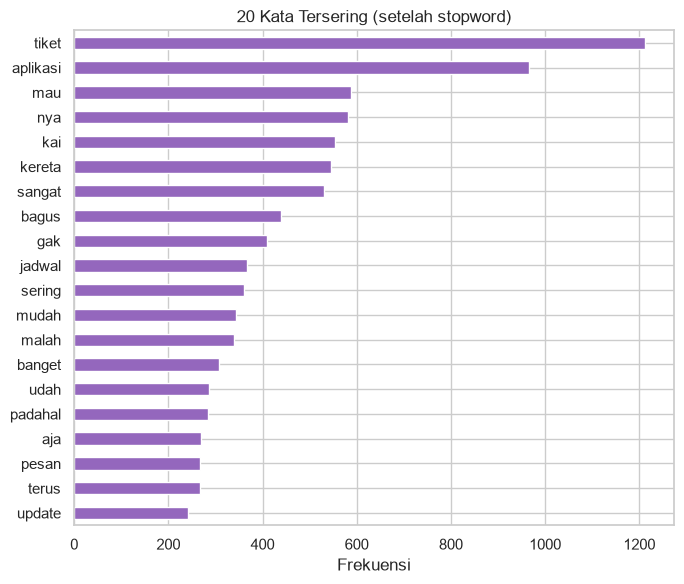

In [6]:
stopwords = set(StopWordRemoverFactory().get_stop_words())

def tokenize(text):
    tokens = re.findall(r"[a-zA-Z]+", str(text).lower())
    return [t for t in tokens if len(t) >= 3 and t not in stopwords]

all_tokens = [t for text in df["content"] for t in tokenize(text)]
top20 = Counter(all_tokens).most_common(20)
for word, freq in top20:
    print(f"{word:>15} : {freq}")

words, freqs = zip(*top20)
ax = pd.Series(freqs, index=words).sort_values().plot(kind="barh", figsize=(7, 6), color="#9467bd")
ax.set_title("20 Kata Tersering (setelah stopword)")
ax.set_xlabel("Frekuensi")
plt.tight_layout()
plt.show()

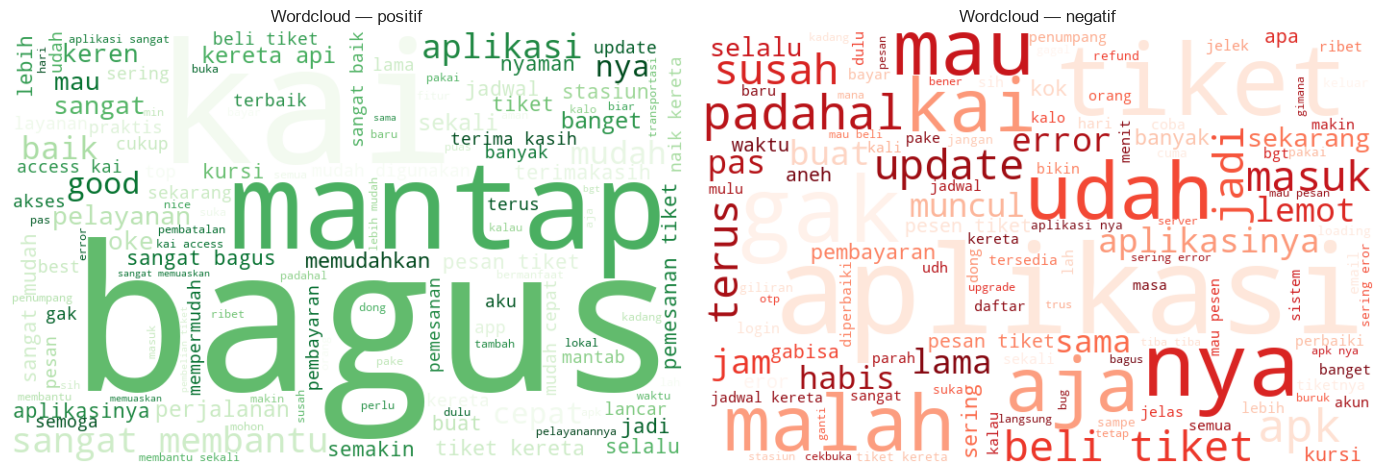

In [7]:
def teks_gabung(label):
    return " ".join(
        " ".join(tokenize(t)) for t in df.loc[df["sentimen"] == label, "content"]
    )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, label, warna in zip(axes, ["positif", "negatif"], ["Greens", "Reds"]):
    wc = WordCloud(
        width=700, height=450, background_color="white",
        colormap=warna, max_words=120, random_state=42,
    ).generate(teks_gabung(label))
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(f"Wordcloud — {label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [8]:
for label in ["positif", "netral", "negatif"]:
    print(f"\n=== Contoh ulasan {label} ===")
    contoh = df.loc[df["sentimen"] == label, ["score", "content"]].head(3)
    for _, row in contoh.iterrows():
        print(f"[{row['score']}] {row['content'][:160]}")


=== Contoh ulasan positif ===
[5] mantappp
[5] ok
[5] Good

=== Contoh ulasan netral ===
[3] Mohon untuk di perbaharui di nomer hp, agar bisa di ganti di nomer saya yang baru, trims
[3] APK-NYA LEMOT PADAHAL WIFINYA ATAU JARINGANNYA CEPET MAU BELI TIKET AJA TULISAN NYA RUTE INI TIDAK TERSEDIA PADAHAL BELI TIKETNYA DI RUTE YANG SERING AKU BELI
[3] daftar gampang tapi pas mau klik untuk beli tiket harus daftar. pas daftar otp email lama sekali.

=== Contoh ulasan negatif ===
[1] kalo ga mau duit lu ilang mending jangan download apk ini mana banyak bug nya!
[1] ketika cancel tiket veritifikasi kode otp sudah benar k tapi selalu tidak bisa. ini sengaja gak bs dicancel atau emang aplikasinya yang gak jelas. dicoba lain w
[1] terlalu sering up -grade2,capek,aktivisasi kaipai butuh waktu,perasaan saldo kaipai sy msh 50k,hangus deh
